# 04 — Kết quả cuối (tái tạo mọi bảng chính của luận văn)

Notebook chỉ **đọc** kết quả đã có trong `runs/` và các tập đóng băng trong `data/` — không chạy model, không tốn tiền.
Kernel: **Python (vdk1)**. Số liệu khớp các bảng trong `PLAN.md` (bảng kết quả tổng, mục S, U, V, W); script gốc của
từng bảng nằm ở `eval/bao_cao/`.

**Tập đánh giá** (mục R): câu và nhãn nháp do ChatGPT sinh theo hướng dẫn bằng lời (không ví dụ, không dữ liệu train),
người dùng duyệt sửa từng nhãn, đóng băng bằng mã băm trước khi chấm. Test sạch 230 câu = 74 rõ ràng · 39 mơ hồ ·
117 ngoài phạm vi; 28 câu than phiền; `mo_ho_4` 129 câu mơ hồ dài. Chấm bằng code (`eval/metrics.py`), không dùng LLM chấm.

**Model triển khai:** LoRA v5 hạt giống 7, checkpoint 2416, gộp adapter → GGUF **q4_K_M** (1,04 GB) + ngưỡng độ tự tin **0,80**.

In [1]:
import json, math, os, sys
from pathlib import Path
GOC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(GOC); sys.path.insert(0, str(GOC))

import matplotlib.pyplot as plt
import pandas as pd
from eval.metrics import cham_mot_cau, cham_toan_bo, doc_output, nhom_cua_dap_an
from eval.so_muc_nen import dem, kq_nguong, LUOI
from gen.records import query_from_call_prompt as cau_cua

# Bảng màu tham chiếu (đã qua validate_palette.js; 3 ô đầu đạt cả khi so mọi cặp). Chữ dùng màu chữ, không màu chuỗi.
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"
CHU, CHU_PHU, LUOI_KE = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": LUOI_KE, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.labelcolor": CHU_PHU,
    "xtick.color": CHU_PHU, "ytick.color": CHU_PHU, "text.color": CHU,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.precision", 1)


def doc(p):
    return [json.loads(x) for x in open(p, encoding="utf-8")]


def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2**n)


def wilson(k, n, z=1.96):
    p = k / n
    t = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return 100 * (p + z * z / (2 * n) - t) / (1 + z * z / n), 100 * (p + z * z / (2 * n) + t) / (1 + z * z / n)


NHOM = {"ro_rang": "Rõ ràng (74)", "mo_ho": "Mơ hồ (39)", "ngoai_pham_vi": "Ngoài phạm vi (117)"}
SACH = doc("data/processed/final/test_vi_sach_v2.jsonl")
BO_SUNG = doc("data/processed/final/test_vi_bo_sung.jsonl")
MH4 = doc("data/processed/final/test_vi_mo_ho_4.jsonl")

## 1. Hành trình kết quả — từ model chưa train tới bản chạy trên máy

Mỗi dòng: điểm trên **test sạch** theo nhóm (%), 28 câu than phiền, `mo_ho_4`. Student = trung bình 2 hạt giống (42, 7)
trừ dòng GGUF (chỉ hạt giống 7 — bản triển khai). Dòng có ngưỡng: câu dưới ngưỡng chuyển thành hỏi lại / từ chối theo token hạng 2 (mục S).

In [2]:
def ket_qua_file(rows_ket_qua, t=0.0):
    "rows có sẵn ket_qua/top_buoc_1 (do_tu_tin) -> % đúng theo tập/nhóm"
    o = {}
    S = [d for d in rows_ket_qua if d["tap"] == "test_vi_sach_v2"]
    for n in NHOM:
        N = [d for d in S if d["nhom"] == n]
        o[n] = 100 * sum(kq_nguong(d, t) == "dung" for d in N) / len(N)
    B = [d for d in rows_ket_qua if d["tap"] == "test_vi_bo_sung"]
    o["28 câu"] = 100 * sum(kq_nguong(d, t) == "dung" for d in B) / len(B) if B else float("nan")
    o["gọi bừa"] = sum(kq_nguong(d, t) == "goi_bua" for d in S)
    return o


def mh4_file(p, t=0.0):
    R = doc(p)
    if "ket_qua" not in R[0]:  # baseline: chỉ có prompt/output -> chấm lại bằng code
        out = {r["prompt"]: r["output"] for r in R}
        return 100 * sum(cham_mot_cau(out[r["prompt"]], r["completion"])[0] == "dung" for r in MH4) / len(MH4)
    return 100 * sum(kq_nguong(d, t) == "dung" for d in R) / len(R)


def baseline(ten):
    a = cham_toan_bo(SACH, {r["prompt"]: r["output"] for r in doc(f"runs/baseline/{ten}_test_vi_sach_v2.jsonl")})
    b = cham_toan_bo(BO_SUNG, {r["prompt"]: r["output"] for r in doc(f"runs/baseline/{ten}_test_vi_bo_sung.jsonl")})
    o = {n: a["theo_nhom"][n]["dung_%"] for n in NHOM}
    o["28 câu"] = b["theo_nhom"]["mo_ho"]["dung_%"]
    o["gọi bừa"] = round(a["ty_le_loi_%"]["goi_bua"] * len(SACH) / 100)
    return o


def tb(*ds):
    return {k: sum(d[k] for d in ds) / len(ds) for k in ds[0]}


def student(mau_test, mau_mh4, t=0.0):
    hat = ("s42", "s7")
    a = tb(*[ket_qua_file(doc(mau_test.format(s=s)), t) for s in hat])
    a["mo_ho_4"] = sum(mh4_file(mau_mh4.format(s=s), t) for s in hat) / 2
    return a


HANG = {
    "1,5B chưa train + schema trong prompt": {**baseline("sip_1_5b"), "mo_ho_4": float("nan")},
    "72B + schema trong prompt (teacher)": {**baseline("sip_72b"), "mo_ho_4": mh4_file("runs/mo_ho_4/sip_72b.jsonl")},
    "Student bản đối chứng (v4)": student("runs/tu_tin/test_v4dc_{s}_ck2206.jsonl", "runs/mo_ho_4/v4dc_{s}.jsonl"),
    "Student full v5": student("runs/tu_tin/test_v5_{s}_ck2416.jsonl", "runs/mo_ho_4/v5_{s}.jsonl"),
    "Student LoRA v5": student("runs/tu_tin/test_lorav5_{s}.jsonl", "runs/mo_ho_4/lorav5_{s}.jsonl"),
    "Student LoRA v5 + ngưỡng 0,85": student("runs/tu_tin/test_lorav5_{s}.jsonl", "runs/mo_ho_4/lorav5_{s}.jsonl", 0.85),
}
Q4 = doc("runs/gguf/test_q4_k_m.jsonl")
q4 = ket_qua_file(Q4, 0.80)
q4["mo_ho_4"] = 100 * sum(kq_nguong(d, 0.80) == "dung" for d in Q4 if d["tap"] == "test_vi_mo_ho_4") / len(MH4)
HANG["GGUF q4_K_M + ngưỡng 0,80 (TRIỂN KHAI, s7)"] = q4
bang1 = pd.DataFrame(HANG).T.rename(columns=NHOM)[[*NHOM.values(), "28 câu", "mo_ho_4", "gọi bừa"]]
bang1

,Rõ ràng (74),Mơ hồ (39),Ngoài phạm vi (117),28 câu,mo_ho_4,gọi bừa
"1,5B chưa train + schema trong prompt",37.8,35.9,31.6,14.3,NaN,74.0
72B + schema trong prompt (teacher),83.8,56.4,94.9,39.3,70.5,6.0
Student bản đối chứng (v4),78.4,69.2,74.8,44.6,48.1,29.5
Student full v5,79.1,76.9,75.6,66.1,73.3,28.5
Student LoRA v5,79.1,76.9,83.3,58.9,78.3,19.5
"Student LoRA v5 + ngưỡng 0,85",70.9,76.9,88.0,58.9,78.3,8.5
"GGUF q4_K_M + ngưỡng 0,80 (TRIỂN KHAI, s7)",73.0,74.4,86.3,53.6,73.6,12.0


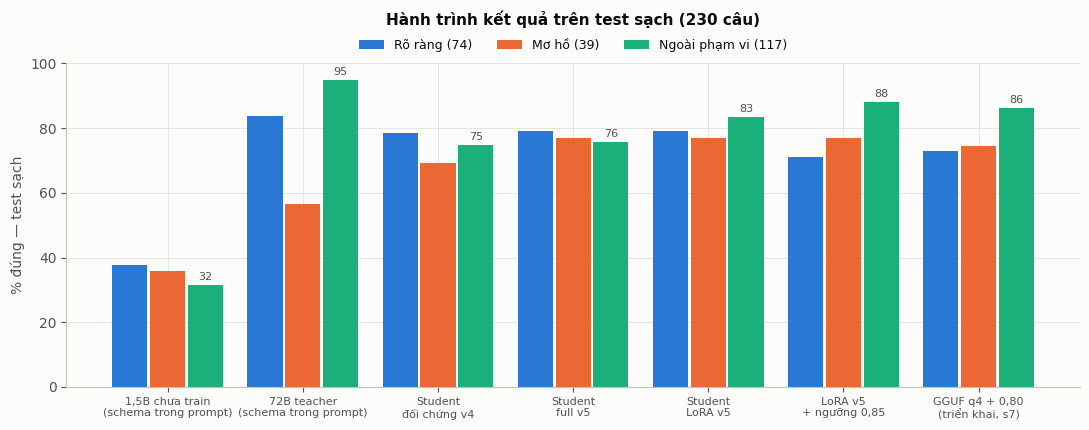

In [3]:
NHAN_NGAN = ["1,5B chưa train\n(schema trong prompt)", "72B teacher\n(schema trong prompt)", "Student\nđối chứng v4",
             "Student\nfull v5", "Student\nLoRA v5", "LoRA v5\n+ ngưỡng 0,85", "GGUF q4 + 0,80\n(triển khai, s7)"]
fig, ax = plt.subplots(figsize=(11, 4.4))
he = list(HANG)
x = range(len(he))
w = 0.26
for i, (n, mau) in enumerate(zip(NHOM, (S1, S2, S3))):
    v = [HANG[h][n] for h in he]
    ax.bar([j + (i - 1) * (w + 0.02) for j in x], v, width=w, color=mau, label=NHOM[n])
ax.set_xticks(list(x)); ax.set_xticklabels(NHAN_NGAN, fontsize=8)
ax.set_ylim(0, 100); ax.set_ylabel("% đúng — test sạch")
ax.set_title("Hành trình kết quả trên test sạch (230 câu)", pad=28)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
for j, h in enumerate(he):  # nhãn chọn lọc: chỉ cột ngoài phạm vi
    ax.text(j + (w + 0.02), HANG[h]["ngoai_pham_vi"] + 1.5, f"{HANG[h]['ngoai_pham_vi']:.0f}", ha="center",
            fontsize=8, color=CHU_PHU)
plt.tight_layout(); plt.show()

**Đọc:** train là cần thiết (1,5B chưa train ~35% → 70–80%). Câu **rõ ràng** student ngang 72B; câu **ngoài phạm vi** là
điểm yếu chung của fine-tune (gọi bừa) — LoRA và ngưỡng thu hẹp khoảng cách. Bản GGUF q4 + 0,80 giữ cùng vùng với bản gốc.

## 2. Student (LoRA v5) so với teacher 72B — kiểm định McNemar từng hạt giống

Cùng câu, so đúng/sai từng cặp. Chỉ kết luận khi **cả hai hạt giống** p < 0,05 cùng chiều.

In [4]:
DAP_AN = {s["prompt"]: s["completion"] for s in SACH}
D72 = {cau_cua(r["prompt"]): cham_mot_cau(r["output"], DAP_AN[r["prompt"]])[0] == "dung"
       for r in doc("runs/baseline/sip_72b_test_vi_sach_v2.jsonl")}
NH = {cau_cua(s["prompt"]): nhom_cua_dap_an(doc_output(s["completion"])) for s in SACH}
dong = []
for s in ("s42", "s7"):
    L = {d["cau"]: d["ket_qua"] == "dung" for d in doc(f"runs/tu_tin/test_lorav5_{s}.jsonl") if d["tap"] == "test_vi_sach_v2"}
    for n in NHOM:
        ks = [c for c in L if NH[c] == n]
        b = sum(L[c] and not D72[c] for c in ks); c_ = sum(D72[c] and not L[c] for c in ks)
        dong.append({"hạt giống": s, "nhóm": NHOM[n], "LoRA %": 100 * sum(L[c] for c in ks) / len(ks),
                     "72B %": 100 * sum(D72[c] for c in ks) / len(ks), "LoRA hơn": b, "72B hơn": c_, "p": mcnemar(b, c_)})
pd.DataFrame(dong).style.format({"LoRA %": "{:.1f}", "72B %": "{:.1f}", "p": "{:.3f}"})

,hạt giống,nhóm,LoRA %,72B %,LoRA hơn,72B hơn,p
0,s42,Rõ ràng (74),79.7,83.8,6,9,0.607
1,s42,Mơ hồ (39),79.5,56.4,11,2,0.022
2,s42,Ngoài phạm vi (117),84.6,94.9,2,14,0.004
3,s7,Rõ ràng (74),78.4,83.8,5,9,0.424
4,s7,Mơ hồ (39),74.4,56.4,10,3,0.092
5,s7,Ngoài phạm vi (117),82.1,94.9,2,17,0.001


## 3. Full fine-tune vs LoRA (cùng dữ liệu v5, cùng hạt giống) và cách B (full, lr 2e-5)

,Rõ ràng (74),Mơ hồ (39),Ngoài phạm vi (117),28 câu,mo_ho_4,gọi bừa
nhánh,,,,,,
Full lr 5e-5,79.1,76.9,75.6,66.1,73.3,28.5
LoRA lr 5e-5,79.1,76.9,83.3,58.9,78.3,19.5
Full lr 2e-5 (cách B),71.6,48.7,76.1,30.4,46.5,28.0


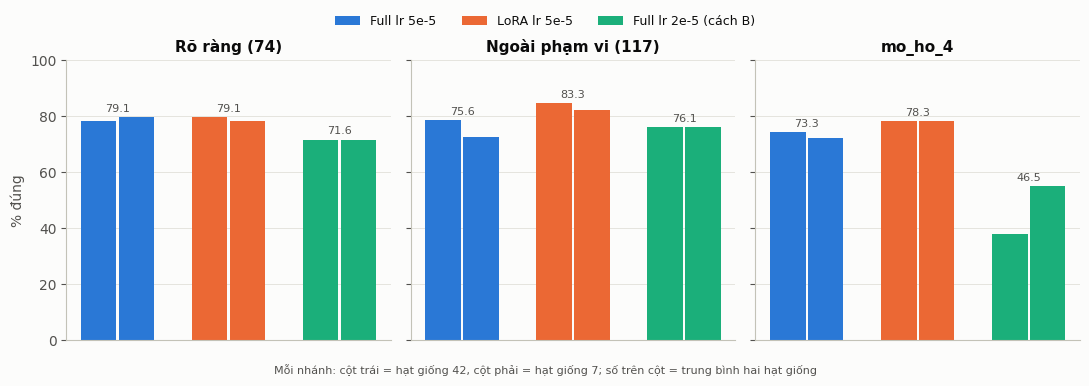

In [5]:
NHANH = {
    "Full lr 5e-5": ("runs/tu_tin/test_v5_{s}_ck2416.jsonl", "runs/mo_ho_4/v5_{s}.jsonl"),
    "LoRA lr 5e-5": ("runs/tu_tin/test_lorav5_{s}.jsonl", "runs/mo_ho_4/lorav5_{s}.jsonl"),
    "Full lr 2e-5 (cách B)": ("runs/tu_tin/test_v5lr2_{s}.jsonl", "runs/mo_ho_4/v5lr2_{s}.jsonl"),
}
dong = []
for ten, (ft, fm) in NHANH.items():
    for s in ("s42", "s7"):
        o = ket_qua_file(doc(ft.format(s=s)))
        dong.append({"nhánh": ten, "hạt giống": s, **{NHOM[k]: o[k] for k in NHOM}, "28 câu": o["28 câu"],
                     "mo_ho_4": mh4_file(fm.format(s=s)), "gọi bừa": o["gọi bừa"]})
bang3 = pd.DataFrame(dong)
display(bang3.groupby("nhánh", sort=False).mean(numeric_only=True))

fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, cot in zip(axs, (NHOM["ro_rang"], NHOM["ngoai_pham_vi"], "mo_ho_4")):
    for i, (ten, mau) in enumerate(zip(NHANH, (S1, S2, S3))):
        v = bang3[bang3["nhánh"] == ten][cot].tolist()
        ax.bar([i - 0.17, i + 0.17], v, width=0.32, color=mau, label=ten if cot == NHOM["ro_rang"] else None)
        ax.text(i, max(v) + 2, f"{sum(v) / 2:.1f}", ha="center", fontsize=8, color=CHU_PHU)
    ax.set_title(cot); ax.set_xticks([]); ax.set_ylim(0, 100)
axs[0].set_ylabel("% đúng")
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06), fontsize=9)
fig.text(0.5, -0.03, "Mỗi nhánh: cột trái = hạt giống 42, cột phải = hạt giống 7; số trên cột = trung bình hai hạt giống",
         ha="center", fontsize=8, color=CHU_PHU)
plt.tight_layout(); plt.show()

**Đọc (mục V):** LoRA **ngang** full ở câu rõ ràng và **từ chối câu ngoài phạm vi tốt hơn nhất quán** (4/4 cặp cùng epoch);
lợi thế ở mo_ho_4 phần lớn do chọn epoch. Giảm lr của full (cách B) **không** làm full từ chối tốt hơn mà làm model học chưa đủ
— theo tiêu chí khoá trước: "vẫn thua". → chọn LoRA làm model triển khai.

## 4. Ngưỡng độ tự tin — chọn trên val+dev, áp lên bản HF và bản nén q4

Luật đã khoá (mục V): ngưỡng **cao nhất** mà số câu rõ ràng đúng trên val+dev giảm ≤ 1% và gọi bừa giảm ≥ 1.

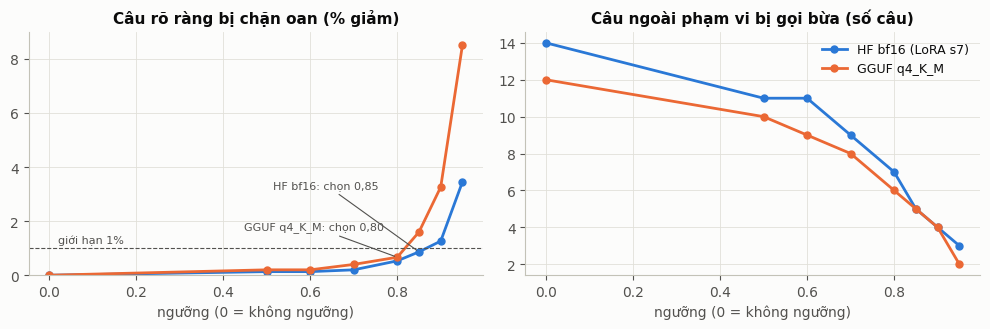

In [6]:
VAL = {"HF bf16 (LoRA s7)": doc("runs/tu_tin/val_lorav5_s7.jsonl"), "GGUF q4_K_M": doc("runs/gguf/val_q4_k_m.jsonl")}
NG = (0.0,) + tuple(t for t in LUOI if t <= 0.95)  # bỏ 0,97 để trục không bị kéo giãn (q4 mất 15% ở đó)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for (ten, R), mau, chon, lech in zip(VAL.items(), (S1, S2), (0.85, 0.80), ((-105, 46), (-110, 20))):
    g = dem(R)
    giam = [100 * (g["ro_rang_dung"] - dem(R, t)["ro_rang_dung"]) / g["ro_rang_dung"] for t in NG]
    gb = [dem(R, t)["goi_bua"] for t in NG]
    axs[0].plot(NG, giam, color=mau, lw=2, marker="o", ms=5, label=ten)
    axs[1].plot(NG, gb, color=mau, lw=2, marker="o", ms=5, label=ten)
    i = NG.index(chon)
    axs[0].annotate(f"{ten.split(' (')[0]}: chọn {chon:.2f}".replace(".", ","), (chon, giam[i]), xytext=lech,
                    textcoords="offset points", fontsize=8, color=CHU_PHU,
                    arrowprops={"arrowstyle": "-", "color": CHU_PHU, "lw": 0.8})
axs[0].axhline(1.0, color=CHU_PHU, lw=0.8, ls="--"); axs[0].text(0.02, 1.2, "giới hạn 1%", fontsize=8, color=CHU_PHU)
axs[0].set_title("Câu rõ ràng bị chặn oan (% giảm)"); axs[0].set_ylim(0, 9)
axs[1].set_title("Câu ngoài phạm vi bị gọi bừa (số câu)")
for ax in axs:
    ax.set_xlabel("ngưỡng (0 = không ngưỡng)")
axs[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Nén 4-bit làm model **kém tự tin hơn một chút**: cùng ngưỡng 0,85, q4 chặn oan câu rõ ràng gấp đôi bản gốc → luật chọn lại ra
**0,80**, ở đó q4 cho kết quả gần như bản gốc ở 0,85. Ngưỡng phải chọn lại cho từng model / bản nén.

### 4b. 74 câu rõ ràng trên test — ngưỡng làm mất gì?

,đúng ngay,"hỏi lại, đề xuất đúng việc",hỏi lại khác,làm sai
LoRA s7 không ngưỡng,58,0,8,8
"LoRA s7 + 0,85",53,5,10,6
"q4 + 0,80 (triển khai)",54,3,11,6


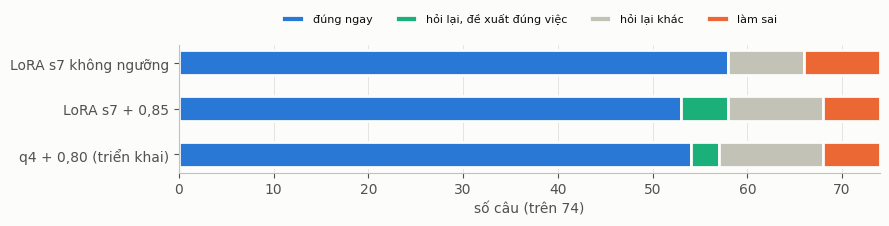

In [7]:
from schema.loader import CATALOG
TU_CHOI, ASK = CATALOG.by_name["irrelevant_function"].nexa_token, CATALOG.nexa_ask


def tach(R, t):
    c = {"đúng ngay": 0, "hỏi lại, đề xuất đúng việc": 0, "hỏi lại khác": 0, "làm sai": 0}
    for d in R:
        if d["tap"] != "test_vi_sach_v2" or d["nhom"] != "ro_rang":
            continue
        (t1, p1), (t2, _) = d["top_buoc_1"][0], d["top_buoc_1"][1]
        if t1 in (TU_CHOI, ASK) or p1 >= t:
            k = d["ket_qua"]
            c["đúng ngay" if k == "dung" else "hỏi lại khác" if k in ("hoi_lai_thua", "tu_choi_nham") else "làm sai"] += 1
        else:
            c["hỏi lại, đề xuất đúng việc" if d["ket_qua"] == "dung" and t2 != TU_CHOI else "hỏi lại khác"] += 1
    return c


T = {"LoRA s7 không ngưỡng": tach(doc("runs/tu_tin/test_lorav5_s7.jsonl"), 0.0),
     "LoRA s7 + 0,85": tach(doc("runs/tu_tin/test_lorav5_s7.jsonl"), 0.85),
     "q4 + 0,80 (triển khai)": tach(Q4, 0.80)}
bang4 = pd.DataFrame(T).T
display(bang4)
fig, ax = plt.subplots(figsize=(9, 2.6))
trai = [0] * len(T)
for cot, mau in zip(bang4.columns, (S1, S3, "#c3c2b7", S2)):
    v = bang4[cot].tolist()
    ax.barh(list(T), v, left=trai, color=mau, label=cot, height=0.55, edgecolor="#fcfcfb", linewidth=2)
    trai = [a + b for a, b in zip(trai, v)]
ax.invert_yaxis(); ax.set_xlim(0, 74); ax.set_xlabel("số câu (trên 74)")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.32))
plt.tight_layout(); plt.show()

Câu bị ngưỡng chặn phần lớn là câu model **vốn làm đúng và vẫn đề xuất đúng việc** — người lái chỉ cần nói "có". Số lần
**làm sai lên xe** giảm. Ngưỡng đổi lỗi nặng (hành động sai) lấy lỗi nhẹ (hỏi lại thừa).

## 5. Nén GGUF — 4 mức trên val+dev (3.036 câu)

,GB,ro_rang_dung,goi_bua,mo_ho_dung,output trùng mốc,|Δp| tb
bản,,,,,,
HF bf16 (mốc),3.55,1506,14,127,3036,0.0000
f16,3.31,1508,14,126,3031,0.0010
q8_0,1.76,1507,15,126,3031,0.0014
q5_K_M,1.20,1505,13,124,3012,0.0044
q4_K_M,1.04,1503,12,125,2998,0.0096


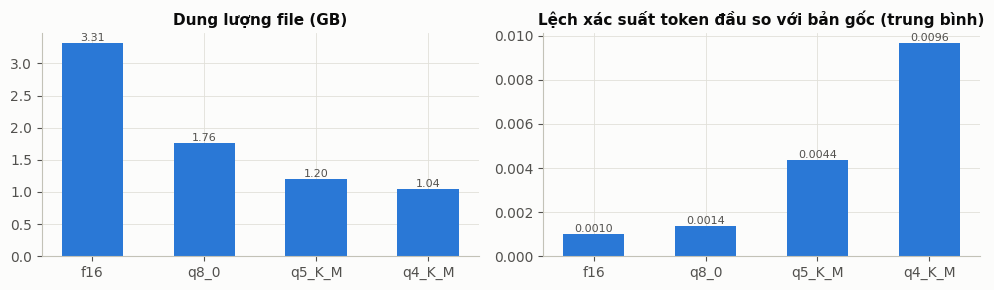

In [8]:
DUNG_LUONG = {"f16": 3.31, "q8_0": 1.76, "q5_K_M": 1.20, "q4_K_M": 1.04}
FILE = {"f16": "val_f16", "q8_0": "val_q8_0", "q5_K_M": "val_q5_k_m", "q4_K_M": "val_q4_k_m"}
MOC = doc("runs/tu_tin/val_lorav5_s7.jsonl")
moc = {(d["tap"], d["cau"]): d for d in MOC}
dong = [{"bản": "HF bf16 (mốc)", "GB": 3.55, **dem(MOC), "output trùng mốc": len(MOC), "|Δp| tb": 0.0}]
for ten, f in FILE.items():
    R = doc(f"runs/gguf/{f}.jsonl")
    cap = [(d, moc[(d["tap"], d["cau"])]) for d in R]
    lech = [abs(d["p_buoc_1"] - m["p_buoc_1"]) for d, m in cap if d["top_buoc_1"][0][0] == m["top_buoc_1"][0][0]]
    dong.append({"bản": ten, "GB": DUNG_LUONG[ten], **dem(R), "output trùng mốc": sum(d["output"] == m["output"] for d, m in cap),
                 "|Δp| tb": sum(lech) / len(lech)})
bang5 = pd.DataFrame(dong).set_index("bản")
display(bang5.style.format({"GB": "{:.2f}", "|Δp| tb": "{:.4f}"}))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.0))
b = bang5.iloc[1:]
axs[0].bar(b.index, b["GB"], color=S1, width=0.55)
axs[0].set_title("Dung lượng file (GB)")
axs[1].bar(b.index, b["|Δp| tb"], color=S1, width=0.55)
axs[1].set_title("Lệch xác suất token đầu so với bản gốc (trung bình)")
for ax, cot, dinh_dang in ((axs[0], "GB", "{:.2f}"), (axs[1], "|Δp| tb", "{:.4f}")):
    for i, v in enumerate(b[cot]):
        ax.text(i, v, dinh_dang.format(v), ha="center", va="bottom", fontsize=8, color=CHU_PHU)
plt.tight_layout(); plt.show()

**Đọc (mục W):** chuyển sang GGUF (f16) **không mất gì**; độ lệch tăng dần theo mức nén. q8 gần như y hệt bản gốc; q4 nhẹ gấp
3,2 lần bản gốc, vẫn đạt luật chất lượng khoá trước (rõ ràng −0,2%, gọi bừa không tăng, mơ hồ −2) → **chọn q4_K_M**.
Chênh 1–3 câu ở nhóm mơ hồ là cỡ nhiễu (q5 còn thấp hơn q4).

*Độ trễ chưa đưa vào notebook:* số đo hiện có lấy trong lúc máy làm việc khác, không cùng điều kiện giữa các bản — sẽ đo lại
có kiểm soát ở bước cắm runtime (PLAN.md mục W).

## 6. Hạn chế cần ghi khi viết luận văn
- Tập đánh giá là câu **LLM sinh** (ChatGPT) + người duyệt — chưa phải câu người lái thật; chưa thử qua giọng nói.
- Test nhỏ (230 câu) và đã dùng nhiều lần; việc đổi model chính sang LoRA dựa trên điểm test (không có tiêu chí khoá trước).
- Ngưỡng chọn trên val (Qwen sinh, dễ hơn test) → trên test mất câu rõ ràng nhiều hơn dự kiến.
- Bản triển khai đo trên **một** hạt giống (s7); `mo_ho_4` của q4 thấp hơn bản gốc 4,7 điểm (p 0,11 — chưa có ý nghĩa).